# Cross-validation across Functions 1-8

Compare the same Gaussian-process kernel candidates across all eight benchmark functions using shared, shuffled five-fold cross-validation within each function. The notebook reports fold-level predictive metrics and visualizes normalized error and uncertainty coverage.

Kernel rankings are comparisons on the supplied observations, not evidence of global optimization performance.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.gaussian_process.kernels import (
    ConstantKernel,
    ExpSineSquared,
    Matern,
    RBF,
    RationalQuadratic,
    WhiteKernel,
)

from bayesian_bbo import CONFIG, FUNCTION_SPECS, load_observations
from bayesian_bbo.validation import cross_validate_kernels

FUNCTION_IDS = tuple(FUNCTION_SPECS)
N_SPLITS = 5
LENGTH_CAPS = {
    1: 31.622776601683793,
    2: 31.622776601683793,
    3: 31.622776601683793,
    4: 10.0,
    5: 100.0,
    6: 31.622776601683793,
    7: 31.622776601683793,
    8: 100.0,
}
plt.style.use("seaborn-v0_8-whitegrid")

## Load observations and define kernels

The loader handles cumulative observations and falls back to the initial data files. Matérn and RBF use ARD length scales; scikit-learn's Rational Quadratic kernel is isotropic. Every kernel's length-scale bound uses the corresponding `LENGTH_CAPS[function_id]`; Exp-Sine-Squared periodicity retains its separate bounds. Each function's outputs are standardized during GP fitting.

### Exp-Sine-Squared kernel

This periodic candidate learns a shared period and length scale across input coordinates. It is most useful when the function has repeating structure; its results here are a comparison, not an assumption that every function is periodic.

In [2]:
WEEK = 2  # read observations recorded up to and including this week
data_candidates = [Path("../../data"), Path("data"), Path("../data")]
data_root = next(
    (path.resolve() for path in data_candidates if (path / "function_1").is_dir()),
    None,
)
if data_root is None:
    raise FileNotFoundError("Could not find the data directory from this notebook's working directory.")

observations_by_function = {
    function_id: load_observations(data_root, function_id, up_to_week=WEEK)
    for function_id in FUNCTION_IDS
}
data_summary = pd.DataFrame(
    [
        {
            "function_id": function_id,
            "observations": len(observations.inputs),
            "dimensions": observations.dimension,
            "output_std": float(np.std(observations.outputs)),
        }
        for function_id, observations in observations_by_function.items()
    ]
)
if (data_summary["observations"] < N_SPLITS).any():
    raise ValueError(f"Each function needs at least {N_SPLITS} observations for this comparison.")

print(f"Data root: {data_root}")
data_summary

Data root: /home/pabloncho/repositories/bayesian-bbo/data


,function_id,observations,dimensions,output_std
0,1,11,2,0.001037
1,2,11,2,0.216960
2,3,16,3,0.085145
3,4,31,4,7.327809
4,5,21,4,357.596904
5,6,21,5,0.466258
6,7,31,6,0.334274
7,8,41,8,0.967807


In [3]:
def make_kernel_candidates(dimension, length_cap):
    def amplitude():
        return ConstantKernel(1.0, (1e-3, 1e3))

    def noise():
        return WhiteKernel(1e-5, (1e-8, 1e1))

    length_bounds = (1e-3, length_cap)
    return {
        "Matérn 3/2": lambda: (
            amplitude()
            * Matern(length_scale=np.ones(dimension), length_scale_bounds=length_bounds, nu=1.5)
            + noise()
        ),
        "Matérn 5/2": lambda: (
            amplitude()
            * Matern(length_scale=np.ones(dimension), length_scale_bounds=length_bounds, nu=2.5)
            + noise()
        ),
        "RBF": lambda: (
            amplitude()
            * RBF(length_scale=np.ones(dimension), length_scale_bounds=length_bounds)
            + noise()
        ),
        "Rational Quadratic": lambda: (
            amplitude()
            * RationalQuadratic(
                length_scale=1.0,
                length_scale_bounds=length_bounds,
                alpha=1.0,
            )
            + noise()
        ),
        "Exp-Sine-Squared": lambda: (
            amplitude()
            * ExpSineSquared(
                length_scale=1.0,
                periodicity=1.0,
                length_scale_bounds=length_bounds,
                periodicity_bounds=(1e-2, 1e2),
            )
            + noise()
        ),
    }

kernel_factories_by_function = {
    function_id: make_kernel_candidates(observations.dimension, LENGTH_CAPS[function_id])
    for function_id, observations in observations_by_function.items()
}
list(kernel_factories_by_function[1])

['Matérn 3/2', 'Matérn 5/2', 'RBF', 'Rational Quadratic', 'Exp-Sine-Squared']

## Run cross-validation

Each function gets its own shuffled folds, reused across that function's kernel candidates. All candidates for a function use its `LENGTH_CAPS[function_id]` length-scale cap. The returned `cv_results` contains one row per function, kernel, and held-out fold. RMSE is also divided by that function's observed output standard deviation (`NRMSE`) to make error scales more comparable across functions.

In [4]:
fold_results = []

for function_id, observations in observations_by_function.items():
    results = cross_validate_kernels(
        observations.inputs,
        observations.outputs,
        kernel_factories_by_function[function_id],
        n_splits=N_SPLITS,
        random_state=CONFIG["random_state"],
        n_restarts_optimizer=CONFIG["n_restarts_optimizer"],
        normalize_y=CONFIG["normalize_y"],
    )
    results.insert(0, "function_id", function_id)
    fold_results.append(results)

cv_results = pd.concat(fold_results, ignore_index=True)

cv_summary = (
    cv_results.groupby(["function_id", "kernel"])[
        ["RMSE", "MAE", "negative_log_predictive_density", "coverage_90", "NRMSE"]
    ]
    .agg(["mean", "std"])
)
cv_summary.columns = [f"{metric}_{statistic}" for metric, statistic in cv_summary.columns]
cv_summary

/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


...

/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 5 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 7 of parameter k1__k2__length_scale is close to the specified upper bound 100.0. Increasing the bound and calling fit again may find a better value.
  warnings.warn(


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-08. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(


RMSE_mean    RMSE_std    MAE_mean  \
function_id kernel                                                   
1           Exp-Sine-Squared      0.000799    0.000982    0.000643   
            Matérn 3/2            0.000800    0.000981    0.000629   
            Matérn 5/2            0.000796    0.000982    0.000624   
            RBF                   0.000797    0.000981    0.000623   
            Rational Quadratic    0.000841    0.000956    0.000691   
2           Exp-Sine-Squared      0.208560    0.112873    0.192044   
            Matérn 3/2            0.184735    0.151811    0.174863   
            Matérn 5/2            0.205167    0.134518    0.187959   
            RBF                   0.200328    0.128544    0.181819   
            Rational Quadratic    0.234201    0.137330    0.220838   
3           Exp-Sine-Squared      0.072608    0.064787    0.054742   
            Matérn 3/2            0.078067    0.066385    0.057175   
            Matérn 5/2            0.081936    0.070436    0.059587   
            RBF                   0.087022    0.063405    0.061238   
            Rational Quadratic    0.064983    0.069399    0.053636   
4           Exp-Sine-Squared      7.282205    1.754057    5.854592   
            Matérn 3/2            2.285275    1.041718    1.796026   
            Matérn 5/2            1.444680    0.670590    1.073065   
            RBF                   4.348002    2.585587    3.618904   
            Rational Quadratic    1.273694    0.511060    1.040417   
5           Exp-Sine-Squared    444.186735  409.055475  361.402916   
            Matérn 3/2           57.034504   17.720172   45.639379   
            Matérn 5/2           89.075655   64.293905   76.051599   
            RBF                 218.046708  200.325379  163.064540   
            Rational Quadratic  138.684654   52.615002  109.840430   
6           Exp-Sine-Squared      0.423368    0.184361    0.374557   
            Matérn 3/2            0.327650    0.080547    0.293422   
            Matérn 5/2            0.389281    0.039338    0.334411   
            RBF                   0.422959    0.024594    0.369361   
            Rational Quadratic    0.269116    0.148553    0.201859   
7           Exp-Sine-Squared      0.328060    0.133451    0.266677   
            Matérn 3/2            0.331055    0.172624    0.262193   
            Matérn 5/2            0.341366    0.169374    0.267313   
            RBF                   0.347250    0.170584    0.276545   
            Rational Quadratic    0.228843    0.040476    0.197761   
8           Exp-Sine-Squared      1.078075    0.155552    0.881074   
            Matérn 3/2            0.161657    0.025027    0.131191   
            Matérn 5/2            0.170455    0.053611    0.135229   
            RBF                   0.249557    0.034854    0.206012   
            Rational Quadratic    0.215836    0.015440    0.165391   

                                   MAE_std  \
function_id kernel                           
1           Exp-Sine-Squared      0.000654   
            Matérn 3/2            0.000663   
            Matérn 5/2            0.000665   
            RBF                   0.000664   
            Rational Quadratic    0.000622   
2           Exp-Sine-Squared      0.107941   
            Matérn 3/2            0.141338   
            Matérn 5/2            0.126989   
            RBF                   0.120649   
            Rational Quadratic    0.136900   
3           Exp-Sine-Squared      0.044937   
            Matérn 3/2            0.042693   
            Matérn 5/2            0.044793   
            RBF                   0.039535   
            Rational Quadratic    0.047598   
4           Exp-Sine-Squared      1.508676   
            Matérn 3/2            0.979203   
            Matérn 5/2            0.535303   
            RBF                   2.210864   
            Rational Quadratic    0.429645   
5           Exp-Sine-Squared    345.736075   
            Matérn 3/2           1

In [5]:
kernel_summary = (
    cv_summary.reset_index()
    .groupby("kernel")[["NRMSE_mean", "coverage_90_mean"]]
    .agg(["mean", "std"])
)
kernel_summary

NRMSE_mean           coverage_90_mean          
                         mean       std             mean       std
kernel                                                            
Exp-Sine-Squared     0.977965  0.147586         0.861984  0.071921
Matérn 3/2           0.608882  0.342220         0.835972  0.085651
Matérn 5/2           0.644341  0.370526         0.810873  0.089393
RBF                  0.765160  0.266483         0.661825  0.150671
Rational Quadratic   0.587489  0.310795         0.875903  0.062614

## Visualize results

The left panel is a heatmap of mean NRMSE for every function and kernel pair, with values annotated in each cell; lower is better. The right panel shows mean 90% interval coverage per function and kernel, with error bars as standard deviation across folds and the nominal 0.90 target as a dashed line.

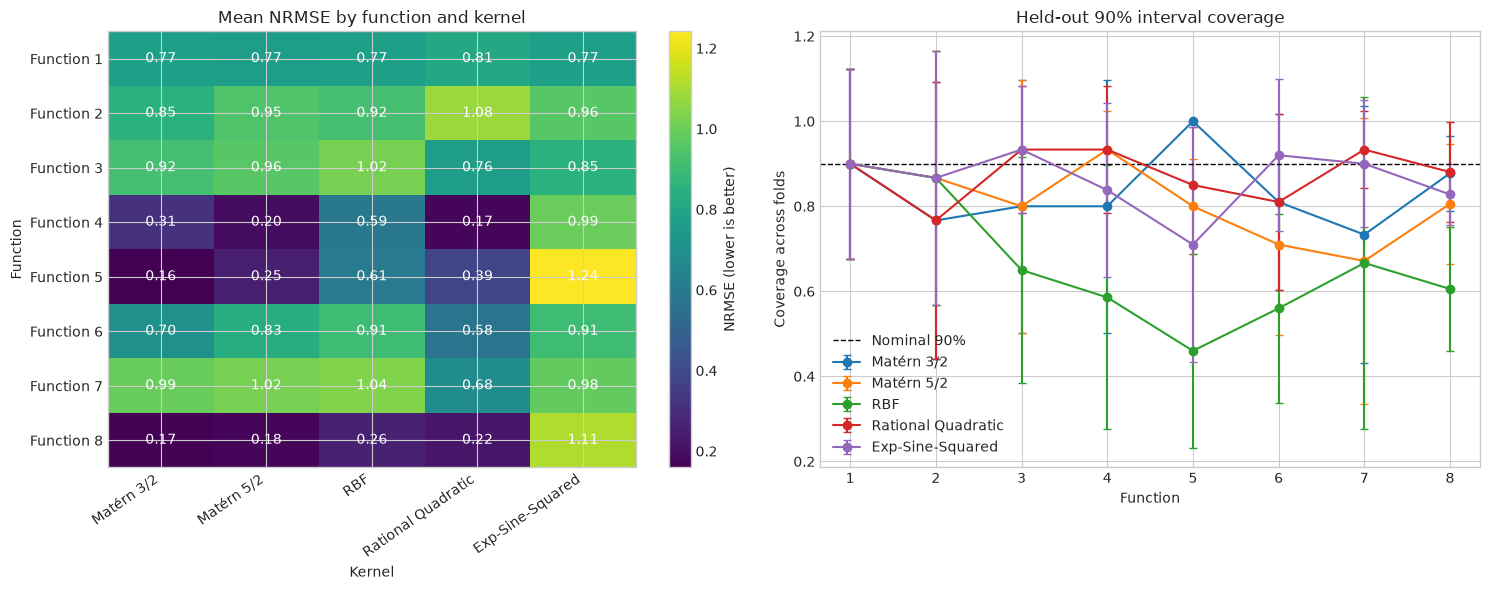

In [6]:
function_ids = sorted(cv_results["function_id"].unique())
kernel_names = list(kernel_factories_by_function[function_ids[0]])

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

nrmse_table = cv_summary["NRMSE_mean"].unstack("kernel").reindex(
    index=function_ids,
    columns=kernel_names,
)
image = axes[0].imshow(nrmse_table, aspect="auto", cmap="viridis")
axes[0].set(
    title="Mean NRMSE by function and kernel",
    xlabel="Kernel",
    ylabel="Function",
)
axes[0].set_xticks(range(len(kernel_names)), kernel_names, rotation=35, ha="right")
axes[0].set_yticks(range(len(function_ids)), [f"Function {i}" for i in function_ids])
for row in range(len(function_ids)):
    for column in range(len(kernel_names)):
        axes[0].text(column, row, f"{nrmse_table.iloc[row, column]:.2f}", ha="center", va="center", color="white")
fig.colorbar(image, ax=axes[0], label="NRMSE (lower is better)")

for kernel_name in kernel_names:
    kernel_rows = cv_summary.xs(kernel_name, level="kernel").reindex(function_ids)
    axes[1].errorbar(
        function_ids,
        kernel_rows["coverage_90_mean"],
        yerr=kernel_rows["coverage_90_std"],
        marker="o",
        capsize=3,
        label=kernel_name,
    )
axes[1].axhline(0.90, color="black", linestyle="--", linewidth=1, label="Nominal 90%")
axes[1].set(
    title="Held-out 90% interval coverage",
    xlabel="Function",
    ylabel="Coverage across folds",
    xticks=function_ids,
)
axes[1].legend()
fig.tight_layout()
plt.show()

## Reading the comparison

Compare kernels primarily within each function: NRMSE helps visualize error across different output scales, but it does not make the benchmark functions statistically interchangeable. Coverage near 0.90 is a rough calibration target, and five folds provide only a small number of estimates. Hyperparameters are refit within each fold; results describe prediction on sampled inputs rather than global optimization performance.

## Kernel choice for Notebook 06

Notebook 06 uses Matérn 3/2 for its submission candidates. Following the within-function comparison above, Matérn 3/2 has the lowest mean RMSE across folds among the three benchmark kernels on six of eight functions (Functions 2, 3, 5, 6, 7 and 8). Matérn 5/2 is lower on Function 4. On Function 1 the three kernels differ by less than 0.0001 in RMSE, which is negligible. RBF has the highest RMSE of the three on six of eight functions.

As a secondary summary, averaging NRMSE across functions gives 0.609 for Matérn 3/2, 0.644 for Matérn 5/2 and 0.765 for RBF. Mean 90% coverage is 0.84, 0.81 and 0.66 respectively. The gap to Matérn 5/2 is small relative to the spread across functions and folds. Rational Quadratic has a lower average NRMSE (0.587) and coverage (0.88), but it is a comparison only and does not inform the choice. The in-sample likelihood in Notebook 02 disagrees with this result.